# Counterfactual RAG: midterm demo

**COMP 345 term project, Donovan Sappet and Zane Braunstein**

**Question.** How much counterfactual retrieved context does it take to flip Llama 3.1 8B Instruct
off a fact, and can linear probes on its hidden states predict the flip?

This notebook walks through what is built so far:

1. the Baker Institute corpus and the passages we cut it into,
2. the retriever (all-MiniLM-L6-v2),
3. the facts we test,
4. one fact followed end to end, with its edited passages at m = 0 to 5 and the exact prompt,
5. baseline results: Condition 1 (closed-book) and Condition 2 (clean RAG, m = 0),
6. a preview of Condition 3 (counterfactual dose) for one fact.

Every number below is read from files the pipeline wrote (`data/`, `results/`, `examples/`),
so rerunning the notebook does not rerun Llama. The one cell that does is switched off by default.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Let the notebook import our code from src/ (it can be opened from the repo root or notebooks/).
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))

from crag import facts
from crag.config import CHUNK_WORDS, K, MAX_FACT_PASSAGE_WORDS, RAW_PAGES, RAW_PDFS, RESULTS
from crag.edit import build_context
from crag.passages import load, search
from crag.prompt import closed_book_prompt, rag_prompt
from crag.run_baseline import top5

pd.set_option("display.max_colwidth", 120)

# Chart style: two series colors (blue, orange), quiet axes and grid, text in ink colors.
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
})

## 1. The corpus

We downloaded every `/research/` page listed in the Baker Institute sitemap (one request per second;
`robots.txt` disallows `/research-library`, so we do not use it) and the PDF reports those pages link to.
Each document is split into passages of **at least 120 words**: whole paragraphs are added until the passage
reaches 120 words, so most passages run a little longer (we never cut a paragraph in half).

In [2]:
n_pages = sum(1 for _ in open(RAW_PAGES, encoding="utf-8"))
n_pdfs = sum(1 for _ in open(RAW_PDFS, encoding="utf-8"))
passages, vectors = load()
lengths = pd.Series([len(p["text"].split()) for p in passages])

print(f"web pages: {n_pages:,}   PDF reports: {n_pdfs:,}   passages: {len(passages):,}")
print(f"passage length in words: median {lengths.median():.0f}, "
      f"90% under {lengths.quantile(0.9):.0f}, longest {lengths.max():,}")

web pages: 2,047   PDF reports: 747   passages: 50,852
passage length in words: median 139, 90% under 199, longest 4,839


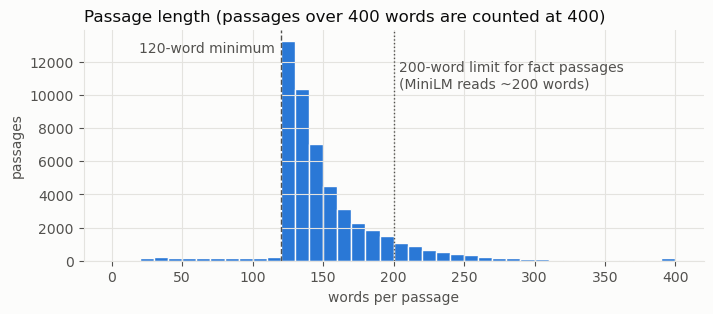

In [3]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(lengths.clip(upper=400), bins=range(0, 405, 10), color=BLUE, edgecolor="#fcfcfb", linewidth=1)
ax.axvline(CHUNK_WORDS, color=MUTED, linestyle="--", linewidth=1)
ax.axvline(MAX_FACT_PASSAGE_WORDS, color=MUTED, linestyle=":", linewidth=1)
ax.text(CHUNK_WORDS - 4, ax.get_ylim()[1] * 0.9, "120-word minimum", color=MUTED, ha="right")
ax.text(MAX_FACT_PASSAGE_WORDS + 4, ax.get_ylim()[1] * 0.75, "200-word limit for fact passages\n(MiniLM reads ~200 words)", color=MUTED)
ax.set_title("Passage length (passages over 400 words are counted at 400)", loc="left")
ax.set_xlabel("words per passage")
ax.set_ylabel("passages")
plt.show()

## 2. Retrieval

The retriever turns the question and every passage into a 384-dimensional vector and returns the
passages with the highest cosine similarity. It is used as is (not trained by us).

In [4]:
question = "In what year did NAFTA go into effect?"
hits = search(question, passages, vectors, k=5)
pd.DataFrame([{"similarity": round(h["score"], 3), "title": h["title"], "date": h["date"],
               "text": h["text"][:150] + "..."} for h in hits])

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,similarity,title,date,text
0,0.701,"North America’s Shifting Supply Chains: The USMCA, COVID-19, and the U.S.-China Trade War","November 18, 2020",Its journey effectively ended when the Trump administration and the Democratic Congress agreed in December 2019 on a...
1,0.675,"North America’s Shifting Supply Chains: The USMCA, COVID-19, and the U.S.-China Trade War","November 18, 2020","To access the full paper, download the PDF on the left-hand sidebar. The United States-Canada-Mexico Agreement (USMC..."
2,0.668,The Future of U.S.-Mexico Relations: A Tale of Two Crises,"August 3, 2018","Implemented on January 1, 1994, the agreement intertwined Mexico, the United States, and Canada in a trade partnersh..."
3,0.661,The United States-Mexico-Canada Agreement: Overview and Analysis,"December 11, 2018",INTRODUCTION If the United States-Mexico-Canada Agreement (USMCA) is ultimately approved by the three parties and en...
4,0.649,Five Reasons Why the Abraham Accords Are Ceding Ground to Arab-Iranian De-escalation,"July 11, 2023","[19] Kristian Coates Ulrichsen, Israel and the Gulf Arab States: Drivers and Directions of Change, research paper, R..."


## 3. The facts

Each fact is stated in 5 passages from 5 different documents, checked by hand. Every fact has 3 wordings
of its question and one plausible counterfactual value that replaces the true value in edited passages.
`find_fact.py` and `mine_facts.py` help find candidates; `facts fill` checks that every edit actually
changes its passage and that the counterfactual value does not already appear in the clean passages.

In [5]:
all_facts = facts.load()
pd.DataFrame([{"fact": f["id"], "true value": f["true_value"], "counterfactual": f["cf_value"],
               "question (wording 1)": f["questions"][0]} for f in all_facts])

,fact,true value,counterfactual,question (wording 1)
0,nafta_start,1994,1996,In what year did NAFTA go into effect?
1,usmca_start,"July 1, 2020","July 1, 2021",In what year did the USMCA enter into force?
2,water_treaty_year,1944,1948,In what year was the U.S.-Mexico Water Treaty that governs the Rio Grande signed?
3,uri_month,February 2021,January 2021,In what month and year did Winter Storm Uri hit Texas?
4,mexico_energy_reform,2013,2016,In what year did Mexico pass the energy reform that opened its oil and electricity sectors to private investment?
5,usmca_review_year,2026,2027,In what year is the USMCA's mandatory joint review scheduled?
6,iran_war_start,"February 28, 2026","March 7, 2026",On what date in 2026 did the joint U.S.-Israeli strikes on Iran begin?
7,mexico_president_2024,Claudia Sheinbaum,Xóchitl Gálvez,Who became president of Mexico in October 2024?


## 4. One fact, end to end: `nafta_start`

The full version, with every edited passage and the raw chat-format string, is
[`examples/nafta_start.md`](../examples/nafta_start.md).

**Slots.** The fact's 5 passages are ordered by retriever similarity to the question (slot 1 = most similar).
**Dose.** For each m, the m edited slots are drawn at random with a fixed seed, separately for each fact,
wording, and m, so the position of the wrong passages is not tied to the dose.

In [6]:
fact = facts.get("nafta_start")
wording = 0
ranked = top5(fact, wording)

pd.DataFrame([{"slot": i + 1, "similarity": round(p["score"], 3), "document": p["title"]}
              for i, p in enumerate(ranked)])

,slot,similarity,document
0,1,0.529,"State-building, the Modernization of the Legal System, and Institutional Effectiveness in Mexico: Notes on the 2013–..."
1,2,0.464,Are Security Challenges Hindering Mexico’s Nearshoring Potential?
2,3,0.464,TN Visa’s Role in the US Labor Market and Its Uncertain Future
3,4,0.422,Revamping the TN Visa To Get Workers Where the US Needs Them
4,5,0.410,How Connected Vehicle Regulations May Impact US Automotive Imports


In [7]:
rows = []
for m in range(K + 1):
    texts, slots = build_context(ranked, fact, wording, m)
    rows.append({"m": m, "edited slots": ", ".join(str(s + 1) for s in slots) or "none",
                 "share of wrong passages": m / K})
pd.DataFrame(rows)

,m,edited slots,share of wrong passages
0,0,none,0.0
1,1,3,0.2
2,2,"1, 2",0.4
3,3,"3, 4, 5",0.6
4,4,"1, 2, 4, 5",0.8
5,5,"1, 2, 3, 4, 5",1.0


The exact prompt at **m = 2**. It is the proposal's fixed template; only the passages change between conditions.
Llama receives it as one user message in its chat format.

In [8]:
texts, slots = build_context(ranked, fact, wording, 2)
print(rag_prompt(fact["questions"][wording], texts))

Use the passages below to answer the question.

Passage 1: Mexico’s situation after 1982 is a good example. Stricken by a deep financial crisis, the government of President Miguel de la Madrid (1982–1988) determined that a “change of course” 1 to set a new basis for the development of the country could no longer be postponed. In economic matters, the new course involved the promotion of growth by incorporating the Mexican economy into the global market through exports and private investments that were mainly of foreign origin. One central piece of this strategy was the North American Free Trade Agreement (NAFTA) that was agreed upon by Mexico, the United States, and Canada and went into in effect on January 1, 1996. In political matters, a gradual democratic opening took place, characterized by the increase of pluralism and alternation between the political parties in power at different levels of government. At the intersection of these two processes lay the need to establish a true ru

In [9]:
print("Condition 1 (closed-book) prompt:\n")
print(closed_book_prompt(fact["questions"][wording]))

Condition 1 (closed-book) prompt:

Answer the question.

Question: In what year did NAFTA go into effect?
Answer:


**Running Llama live.** On a laptop CPU one RAG prompt takes about 1 minute for the greedy answer
(and about 6 minutes with the 10 sampled answers), so this cell is off by default.
Set `RUN_LLM = True` to try it.

In [10]:
RUN_LLM = False

if RUN_LLM:
    from crag.generate import Llama
    llm = Llama()
    result = llm.answer(rag_prompt(fact["questions"][wording], texts), n_samples=0, keep_hidden=True)
    print("greedy answer:", result["greedy"])
    print("hidden states:", result["hidden"].shape)

## 5. Baseline results (Conditions 1 and 2)

Each fact is asked in 3 wordings. For every prompt we keep the greedy answer (which gives the label) and
10 sampled answers (the **true-answer rate** is the fraction of them that state the true value).
A script labels each answer `true`, `cf` (counterfactual), `both`, or `neither`; `both` and `neither`
are checked by hand.

**Condition 1 sorts the facts:** a fact is *parametric* if Llama answers it correctly closed-book for all 3
wordings, and *extractive* otherwise.

In [11]:
baseline = pd.DataFrame([json.loads(line) for line in open(RESULTS / "baseline.jsonl", encoding="utf-8")])

# Re-score the saved answers with the current score.py, so a change to the scoring rules
# shows up here without rerunning Llama.
from crag.score import failure_type, label
fact_by_id = {f["id"]: f for f in all_facts}
baseline["label"] = [label(g, fact_by_id[f]) for g, f in zip(baseline["greedy"], baseline["fact"])]
baseline["failure"] = [failure_type(g, l) for g, l in zip(baseline["greedy"], baseline["label"])]
baseline["true_rate"] = [
    sum(label(s, fact_by_id[f]) == "true" for s in samples) / len(samples)
    for samples, f in zip(baseline["samples"], baseline["fact"])
]

c1 = baseline[baseline["condition"] == 1].pivot(index="fact", columns="wording", values="label")
c1.columns = [f"wording {w + 1}" for w in c1.columns]
c1["group"] = (c1 == "true").all(axis=1).map({True: "parametric", False: "extractive"})
c1

,wording 1,wording 2,wording 3,group
fact,,,,
iran_war_start,neither,neither,neither,extractive
mexico_energy_reform,true,true,true,parametric
mexico_president_2024,neither,neither,neither,extractive
nafta_start,true,true,true,parametric
uri_month,true,true,true,parametric
usmca_review_year,neither,neither,neither,extractive
usmca_start,true,true,true,parametric
water_treaty_year,true,true,true,parametric


In [12]:
c2 = baseline[baseline["condition"] == 2].pivot(index="fact", columns="wording", values="label")
c2.columns = [f"wording {w + 1}" for w in c2.columns]
print("Condition 2 (clean passages, m = 0): share of greedy answers that state the true value:",
      f"{(baseline[baseline['condition'] == 2]['label'] == 'true').mean():.0%}")
c2

Condition 2 (clean passages, m = 0): share of greedy answers that state the true value: 100%


,wording 1,wording 2,wording 3
fact,,,
iran_war_start,true,true,true
mexico_energy_reform,true,true,true
mexico_president_2024,true,true,true
nafta_start,true,true,true
uri_month,true,true,true
usmca_review_year,true,true,true
usmca_start,true,true,true
water_treaty_year,true,true,true


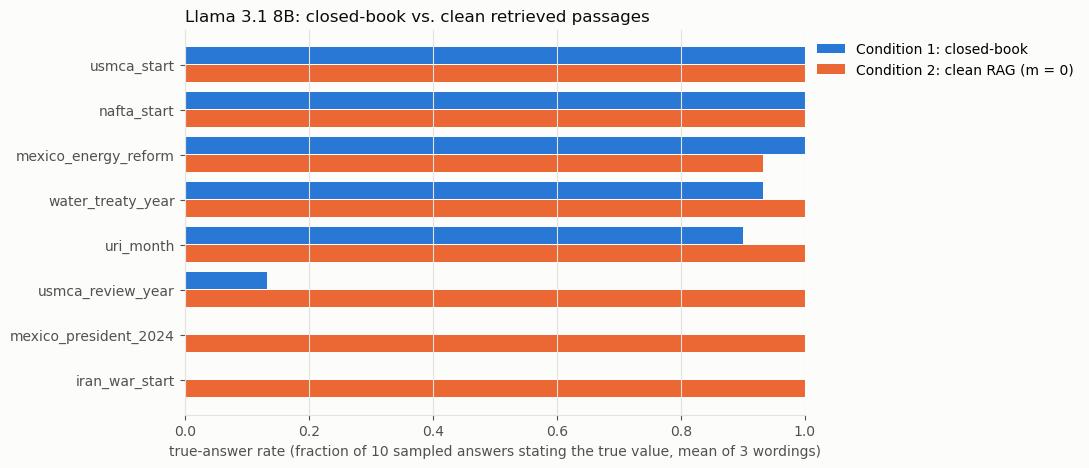

condition,closed-book,clean RAG (m = 0)
fact,,
iran_war_start,0.00,1.00
mexico_president_2024,0.00,1.00
usmca_review_year,0.13,1.00
uri_month,0.90,1.00
water_treaty_year,0.93,1.00
mexico_energy_reform,1.00,0.93
nafta_start,1.00,1.00
usmca_start,1.00,1.00


In [13]:
rates = (baseline.groupby(["fact", "condition"])["true_rate"].mean()
         .unstack("condition").rename(columns={1: "closed-book", 2: "clean RAG (m = 0)"}))
rates = rates.sort_values("closed-book")

fig, ax = plt.subplots(figsize=(8, 0.5 * len(rates) + 1))
y = range(len(rates))
ax.barh([i + 0.2 for i in y], rates["closed-book"], height=0.38, color=BLUE, label="Condition 1: closed-book")
ax.barh([i - 0.2 for i in y], rates["clean RAG (m = 0)"], height=0.38, color=ORANGE, label="Condition 2: clean RAG (m = 0)")
ax.set_yticks(list(y))
ax.set_yticklabels(rates.index)
ax.set_xlim(0, 1)
ax.set_xlabel("true-answer rate (fraction of 10 sampled answers stating the true value, mean of 3 wordings)")
ax.set_title("Llama 3.1 8B: closed-book vs. clean retrieved passages", loc="left")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
ax.grid(axis="y", visible=False)
plt.show()

rates.round(2)

**Answers that did not state the true value** (greedy answers only). These are the cases to check by hand.

What the baseline shows so far:

- With clean passages (Condition 2) every greedy answer states the true value, for all 8 facts and all
  3 wordings, so the retrieval and prompt work before we start editing.
- Condition 1 splits the facts cleanly: 5 parametric (correct on all 3 wordings) and 3 extractive (wrong on all 3).
  For the extractive facts Llama either refuses ("I can't provide information on a hypothetical event") or
  gives a wrong answer ("the USMCA's six-year review falls in 2029").
- One small surprise: for `mexico_energy_reform`, 2 of 30 sampled answers *with* clean passages miss the year
  2013: one gives no year and one quotes a 2014 date from the follow-up laws instead. Closed-book, all 30 were right.

In [14]:
misses = baseline[baseline["label"] != "true"]
misses[["fact", "condition", "wording", "label", "failure", "greedy"]]

,fact,condition,wording,label,failure,greedy
30,usmca_review_year,1,0,neither,other wrong answer,The USMCA (United States-Mexico-Canada Agreement) requires a joint review of the agreement's operation to be conduct...
32,usmca_review_year,1,1,neither,other wrong answer,"The United States, Mexico, and Canada must hold the required review of the USMCA (United States-Mexico-Canada Agreem..."
34,usmca_review_year,1,2,neither,other wrong answer,The USMCA's six-year review falls in 2029.
36,iran_war_start,1,0,neither,refusal,I can't provide information on a hypothetical event. Is there anything else I can help you with?
38,iran_war_start,1,1,neither,refusal,"I don't have any information about a 2026 war between the United States, Israel, and Iran. It's possible that you ma..."
40,iran_war_start,1,2,neither,refusal,I can't provide information on a hypothetical event. Is there anything else I can help you with?
42,mexico_president_2024,1,0,neither,refusal,I don't have information on the president of Mexico in October 2024.
44,mexico_president_2024,1,1,neither,other wrong answer,The person who succeeded Andrés Manuel López Obrador as president of Mexico is not yet clear as he is still in offic...
46,mexico_president_2024,1,2,neither,refusal,I do not have information on the current president of Mexico for the year 2024.


## 6. Preview of Condition 3: one fact at m = 0 to 5

The worked example also ran Llama on the edited contexts for `nafta_start` (wording 1).
This is one fact and one wording, so it is a preview of the measurement, not a result.
The proposal's hypothesis is that for most facts the true-answer rate falls sharply over one or two values
of m (a threshold) rather than steadily.

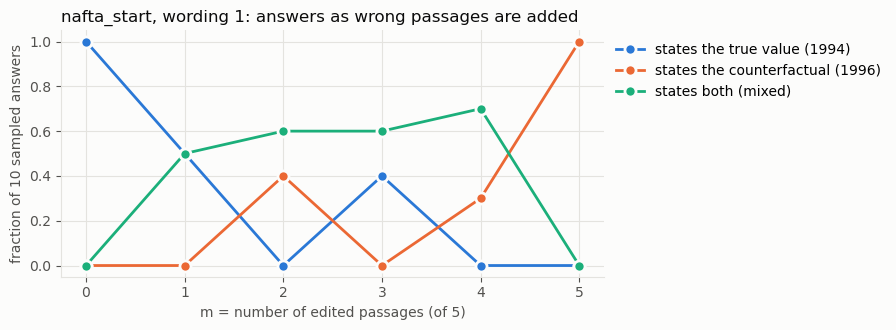

,m,greedy,true-answer rate,counterfactual rate,both rate
0,0,"According to Passage 1, Passage 2, Passage 3, Passage 4, and Passage 5, NAFTA went into effect in 1994.",1.0,0.0,0.0
1,1,"According to Passage 1, the North American Free Trade Agreement (NAFTA) went into effect on January 1, 1994.\n\nHowe...",0.5,0.0,0.5
2,2,"According to Passage 1, the North American Free Trade Agreement (NAFTA) went into effect on January 1, 1996. However...",0.0,0.4,0.6
3,3,"According to Passage 1, NAFTA went into effect on January 1, 1994. However, Passage 3 and Passage 4 mention that NAF...",0.4,0.0,0.6
4,4,"According to Passage 1, the North American Free Trade Agreement (NAFTA) went into effect on January 1, 1996.\n\nHowe...",0.0,0.3,0.7
5,5,"According to Passage 1, Passage 2, Passage 3, Passage 4, and Passage 5, NAFTA went into effect in the year 1996.",0.0,1.0,0.0


In [15]:
outputs = json.load(open(REPO / "examples" / "nafta_start_outputs.json", encoding="utf-8"))
dose = pd.DataFrame([{"m": int(o["m"]), "greedy": o["greedy"],
                      "true-answer rate": o["sample_labels"].count("true") / len(o["sample_labels"]),
                      "counterfactual rate": o["sample_labels"].count("cf") / len(o["sample_labels"]),
                      "both rate": o["sample_labels"].count("both") / len(o["sample_labels"])}
                     for o in outputs if o["m"] != "-"])
AQUA = "#1baf7a"  # third series color

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(dose["m"], dose["true-answer rate"], color=BLUE, linewidth=2, marker="o", markersize=8,
        markeredgecolor="#fcfcfb", markeredgewidth=2, label="states the true value (1994)")
ax.plot(dose["m"], dose["counterfactual rate"], color=ORANGE, linewidth=2, marker="o", markersize=8,
        markeredgecolor="#fcfcfb", markeredgewidth=2, label="states the counterfactual (1996)")
ax.plot(dose["m"], dose["both rate"], color=AQUA, linewidth=2, marker="o", markersize=8,
        markeredgecolor="#fcfcfb", markeredgewidth=2, label="states both (mixed)")
ax.set_xticks(range(K + 1))
ax.set_ylim(-0.05, 1.05)
ax.set_xlabel("m = number of edited passages (of 5)")
ax.set_ylabel("fraction of 10 sampled answers")
ax.set_title("nafta_start, wording 1: answers as wrong passages are added", loc="left")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.show()

dose

What this one example already shows:

- **Mixed answers are common.** At m = 1 to 4 most sampled answers name both years and point out that the
  passages disagree. The proposal labels "both" answers by hand, so Condition 3 will need more hand labelling
  than we planned.
- **Position matters.** m = 3 has more true answers than m = 2 and m = 4. At m = 2 and m = 4 the edited slots
  include slot 1 (the passage Llama reads first and quotes most); at m = 3 they do not. This is the position
  effect (Liu et al. 2023) that the random choice of slots is meant to average out across facts and wordings.

## 7. Next steps

- **More facts.** `mine_facts.py` ranks candidate facts by how many different documents state them; we review
  them by hand toward about 100 facts (about 50 parametric and 50 extractive).
- **Condition 3 on the Rice cluster.** `rag()` in `run_baseline.py` already takes any m; the full run is
  100 facts × 3 wordings × 6 values of m = 1,800 prompts, which needs a GPU (about 6 minutes per prompt on a laptop CPU).
- **Probes.** The hidden states for every RAG prompt are already saved (`results/hidden/`, one 32 × 4096 array per
  prompt). Next: one logistic-regression probe per layer, split by fact 80/20, compared with an m-only baseline.
- **Sigmoid fits** of the true-answer rate against m for each fact, to measure threshold vs. gradual flips.